# 05 · When It Wins and Loses

Naive Bayes is neither a toy nor a universal tool. This notebook draws the precise regime
where the "wrong" model is the right choice — and where it genuinely fails.

* **Wins:** scarce data (it does not overfit), high-dimensional sparse features, and as a
  fast strong baseline.
* **Loses:** strongly correlated features (notebook 04) and problems where feature
  *interactions* carry the signal — which the independence assumption cannot represent.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from src import artifacts
from src.config import SETTINGS
from src.datasets import synthetic
from src.evaluation.data_efficiency import accuracy_vs_size
from src.models import GaussianNB, MultinomialNB
from src.visualisation import plot_data_efficiency

np.set_printoptions(precision=4, suppress=True)

## 1. Data efficiency: Naive Bayes wins when data is scarce

On data with correlated features (so Naive Bayes is slightly mis-specified), the simple
model still wins at small sample sizes because it has far less to estimate and cannot
overfit. Logistic regression, more flexible, overtakes once it has enough data to pin down
its weights. There is a clear crossover.

  n=   20:  NB=0.747  LogReg=0.717   -> NB leads
  n=   40:  NB=0.756  LogReg=0.731   -> NB leads
  n=   80:  NB=0.754  LogReg=0.734   -> NB leads
  n=  160:  NB=0.756  LogReg=0.751   -> NB leads
  n=  320:  NB=0.754  LogReg=0.752   -> NB leads
  n=  640:  NB=0.756  LogReg=0.757   -> LogReg leads
  n= 1280:  NB=0.757  LogReg=0.753   -> NB leads

Logistic regression overtakes at about n = 640


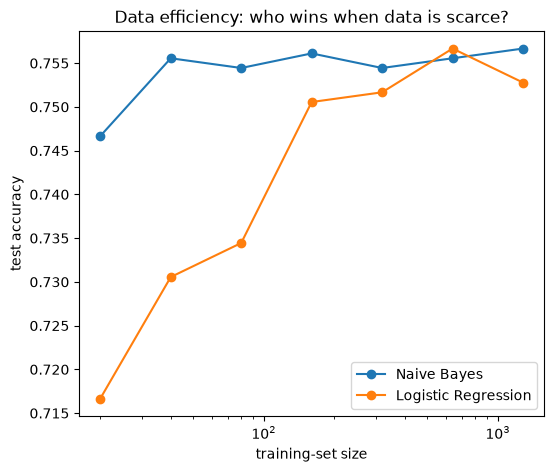

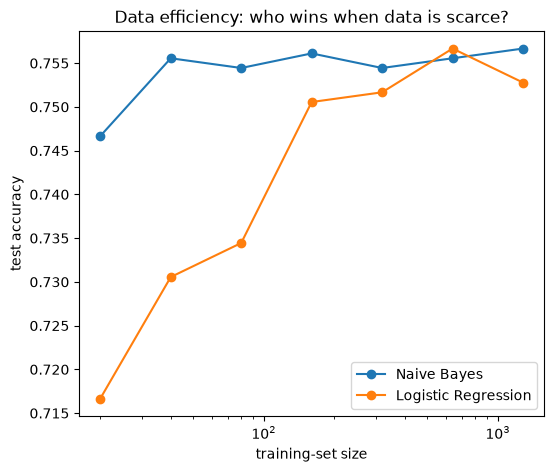

In [2]:
X, y = synthetic.make_correlated_data(
    n_samples=6000, n_features=10, correlation=0.5, class_sep=1.0, seed=1
)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SETTINGS.seed)
sizes = SETTINGS.synthetic.sample_sizes

nb_sizes, nb_acc = accuracy_vs_size(GaussianNB, X_tr, y_tr, X_te, y_te, sizes)
lr_sizes, lr_acc = accuracy_vs_size(
    lambda: LogisticRegression(max_iter=2000), X_tr, y_tr, X_te, y_te, sizes
)

crossover = next((n for n, a, b in zip(nb_sizes, nb_acc, lr_acc) if b > a), None)
for n, a, b in zip(nb_sizes, nb_acc, lr_acc):
    lead = "NB" if a > b else "LogReg"
    print(f"  n={n:>5}:  NB={a:.3f}  LogReg={b:.3f}   -> {lead} leads")
print(f"\nLogistic regression overtakes at about n = {crossover}")

fig = plot_data_efficiency(nb_sizes, {"Naive Bayes": nb_acc, "Logistic Regression": lr_acc})
artifacts.save_fig(fig, "05_data_efficiency")
artifacts.save_json(
    {
        "sizes": nb_sizes,
        "naive_bayes_accuracy": nb_acc,
        "logistic_regression_accuracy": lr_acc,
        "crossover_size": crossover,
    },
    "05_data_efficiency",
)
fig

## 2. High-dimensional, sparse: competitive at a fraction of the cost

Give both models many features and Naive Bayes stays competitive while training far faster —
the setting (bag-of-words text) where it earned its reputation.

In [3]:
Xh, yh = synthetic.make_count_data(n_samples=8000, n_features=500, seed=2)
Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(Xh, yh, test_size=0.3, stratify=yh, random_state=SETTINGS.seed)

start = time.perf_counter()
nb = MultinomialNB(alpha=1.0).fit(Xh_tr, yh_tr)
nb_time = time.perf_counter() - start
nb_hi = float((nb.predict(Xh_te) == yh_te).mean())

start = time.perf_counter()
lr = LogisticRegression(max_iter=2000).fit(Xh_tr, yh_tr)
lr_time = time.perf_counter() - start
lr_hi = float((lr.predict(Xh_te) == yh_te).mean())

print(f"Multinomial NB : accuracy={nb_hi:.3f}  train={nb_time * 1000:.0f} ms")
print(f"Logistic Reg.  : accuracy={lr_hi:.3f}  train={lr_time * 1000:.0f} ms")
print(f"Naive Bayes trained ~{lr_time / nb_time:.0f}x faster")

artifacts.save_json(
    {
        "n_features": 500,
        "naive_bayes": {"accuracy": nb_hi, "train_seconds": nb_time},
        "logistic_regression": {"accuracy": lr_hi, "train_seconds": lr_time},
        "nb_speedup": float(lr_time / nb_time),
    },
    "05_high_dimensional",
)

Multinomial NB : accuracy=1.000  train=10 ms
Logistic Reg.  : accuracy=1.000  train=118 ms
Naive Bayes trained ~12x faster


PosixPath('/workspaces/naive_bayes_101/outputs/data/05_high_dimensional.json')

## 3. Where it fails: feature interactions

If the signal lives in the *interaction* of features rather than in any feature alone, the
independence assumption cannot see it. The textbook case is XOR: each feature on its own is
nearly uninformative on its own, and only their combination carries signal. Naive Bayes lands
just above chance, and more data will not rescue it — until you hand-build the interaction
feature, which it then uses happily.

In [4]:
rng = np.random.default_rng(0)
n = 4000
f = rng.standard_normal((n, 2))
y_xor = ((f[:, 0] > 0) ^ (f[:, 1] > 0)).astype(int)
Xx_tr, Xx_te, yx_tr, yx_te = train_test_split(f, y_xor, test_size=0.3, random_state=SETTINGS.seed)

nb_raw = GaussianNB().fit(Xx_tr, yx_tr)
acc_raw = float((nb_raw.predict(Xx_te) == yx_te).mean())

# Add the interaction term the independence assumption can't construct on its own.
Xi_tr = np.column_stack([Xx_tr, Xx_tr[:, 0] * Xx_tr[:, 1]])
Xi_te = np.column_stack([Xx_te, Xx_te[:, 0] * Xx_te[:, 1]])
nb_interaction = GaussianNB().fit(Xi_tr, yx_tr)
acc_interaction = float((nb_interaction.predict(Xi_te) == yx_te).mean())

print(f"XOR, raw features          : accuracy = {acc_raw:.3f}  (barely above chance)")
print(f"XOR, with interaction term : accuracy = {acc_interaction:.3f}")

artifacts.save_json(
    {"xor_raw_accuracy": acc_raw, "xor_with_interaction_accuracy": acc_interaction},
    "05_interaction_failure",
)

XOR, raw features          : accuracy = 0.613  (barely above chance)
XOR, with interaction term : accuracy = 0.949


PosixPath('/workspaces/naive_bayes_101/outputs/data/05_interaction_failure.json')

## Takeaway

Reach for Naive Bayes when data is scarce, features are many and sparse, or you need a fast,
interpretable baseline a heavier model must beat. Avoid relying on it when features are
strongly correlated or the signal is in their interactions. The next notebook turns this
into a one-page decision guide.